In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv(r"D:\CSE276 project\dataset\cyclone.csv")
df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 68624 entries, 0 to 68623
Data columns (total 18 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   Unnamed: 0                                                68624 non-null  int64  
 1   International number ID                                   68624 non-null  int64  
 2   year                                                      68624 non-null  int64  
 3   month                                                     68624 non-null  int64  
 4   day                                                       68624 non-null  int64  
 5   hour                                                      68624 non-null  int64  
 6   grade                                                     68624 non-null  str    
 7   Latitude of the center                                    68624 non-null  int64  
 8   Longitude of the center    

In [2]:
selected_columns = [
    "year",
    "month",
    "day",
    "hour",
    "grade",
    "Latitude of the center",
    "Longitude of the center",
    "Central pressure"
]

data = df[selected_columns].copy()

print("Dataset shape:", data.shape)
data.head()

Dataset shape: (68624, 8)


,year,month,day,hour,grade,Latitude of the center,Longitude of the center,Central pressure
0,1951,2,19,6,Tropical Depression,200,1385,1010
1,1951,2,19,12,Tropical Depression,200,1385,1010
2,1951,2,19,18,Tropical Depression,230,1421,1000
3,1951,2,20,0,Tropical Cyclone of TS intensity or higher,250,1460,994
4,1951,2,20,6,Tropical Cyclone of TS intensity or higher,276,1506,994


In [3]:
print(data.isnull().sum())

year                       0
month                      0
day                        0
hour                       0
grade                      0
Latitude of the center     0
Longitude of the center    0
Central pressure           0
dtype: int64


In [4]:
X = data.drop("grade", axis=1)
y = data["grade"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   year  month  day  hour  Latitude of the center  Longitude of the center  \
0  1951      2   19     6                     200                     1385   
1  1951      2   19    12                     200                     1385   
2  1951      2   19    18                     230                     1421   
3  1951      2   20     0                     250                     1460   
4  1951      2   20     6                     276                     1506   

   Central pressure  
0              1010  
1              1010  
2              1000  
3               994  
4               994  

Target:
0                           Tropical Depression
1                           Tropical Depression
2                           Tropical Depression
3    Tropical Cyclone of TS intensity or higher
4    Tropical Cyclone of TS intensity or higher
Name: grade, dtype: str


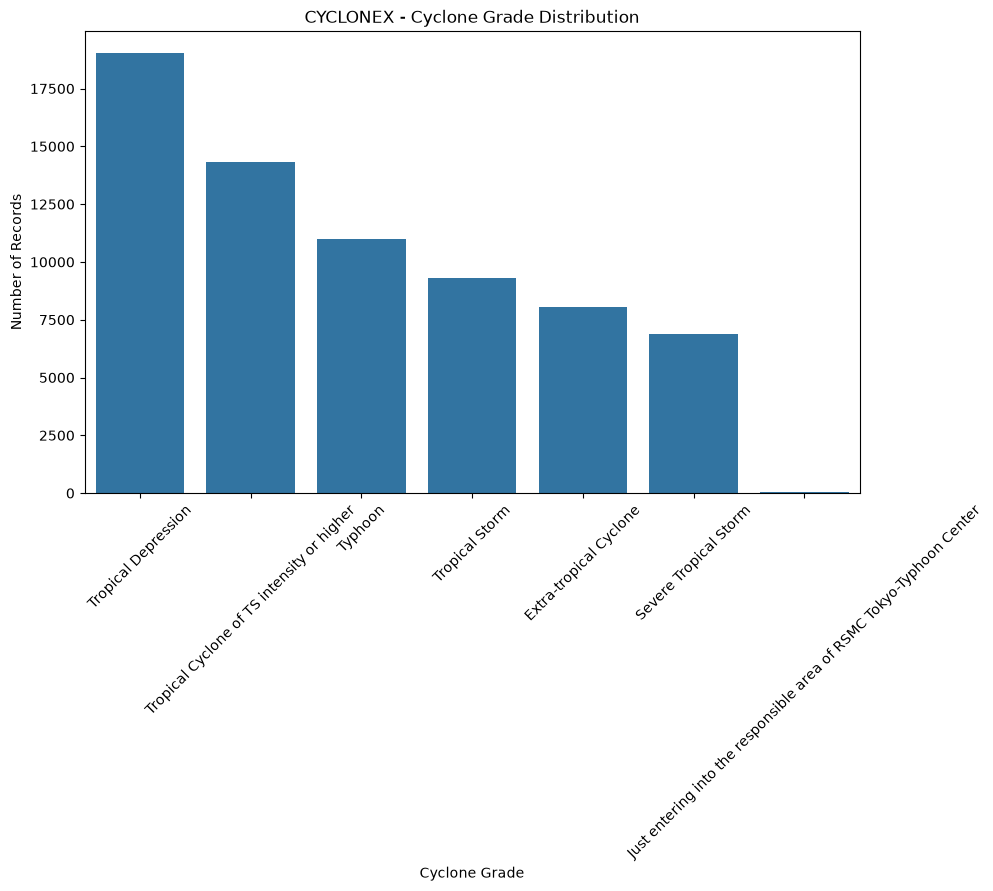

In [5]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=data,
    x="grade",
    order=data["grade"].value_counts().index
)

plt.title("CYCLONEX - Cyclone Grade Distribution")
plt.xlabel("Cyclone Grade")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.savefig("cyclonex_figures/grade_distribution.png", dpi=300)
plt.show()

In [6]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Grade mapping:")

for i, grade in enumerate(label_encoder.classes_):
    print(i, ":", grade)

Grade mapping:
0 : Extra-tropical Cyclone
1 : Just entering into the responsible area of RSMC Tokyo-Typhoon Center
2 : Severe Tropical Storm
3 : Tropical Cyclone of TS intensity or higher
4 : Tropical Depression
5 : Tropical Storm
6 : Typhoon


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (54899, 7)
Testing data: (13725, 7)


In [8]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=400,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [9]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Accuracy: 0.9154098360655738

Classification Report:
                                                                      precision    recall  f1-score   support

                                              Extra-tropical Cyclone       0.89      0.94      0.92      1609
Just entering into the responsible area of RSMC Tokyo-Typhoon Center       1.00      1.00      1.00         6
                                               Severe Tropical Storm       0.86      0.88      0.87      1379
                          Tropical Cyclone of TS intensity or higher       0.95      0.95      0.95      2865
                                                 Tropical Depression       0.93      0.89      0.91      3807
                                                      Tropical Storm       0.83      0.87      0.85      1862
                                                             Typhoon       0.97      0.96      0.97      2197

                                                            accur

In [10]:
import os
import joblib

# Create models directory
model_dir = r"D:\CSE276 project\models"
os.makedirs(model_dir, exist_ok=True)

# Save model, encoder and feature names together
model_bundle = {
    "model": model,
    "label_encoder": label_encoder,
    "features": list(X.columns)
}

model_path = os.path.join(model_dir, "cyclone_model.joblib")

joblib.dump(model_bundle, model_path)

print("Model saved successfully!")
print(model_path)

Model saved successfully!
D:\CSE276 project\models\cyclone_model.joblib


In [11]:
# from xgboost import XGBClassifier
# model=XGBClassifier(n_estimators=100,
#     learning_rate=0.1,
#     max_depth=3,
#     random_state=42,
#     eval_metric="logloss")
# model.fit(X_train,y_train);
# y_pred=model.predict(X_test)
# accuracy_score(y_test,y_pred)

Training Accuracy: 99.68 %
Testing Accuracy: 91.54 %


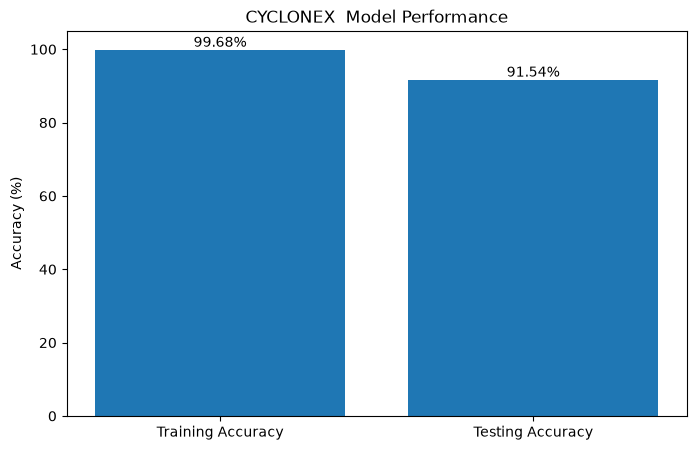

In [12]:
from sklearn.metrics import accuracy_score

train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)

print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")

plt.figure(figsize=(8, 5))

plt.bar(
    ["Training Accuracy", "Testing Accuracy"],
    [train_accuracy * 100, test_accuracy * 100]
)

plt.ylabel("Accuracy (%)")
plt.title("CYCLONEX  Model Performance")
plt.ylim(0, 105)

for i, value in enumerate([train_accuracy, test_accuracy]):
    plt.text(i, value * 100 + 1, f"{value*100:.2f}%", ha="center")

plt.savefig("cyclonex_figures/model_accuracy.png", dpi=300)
plt.show()

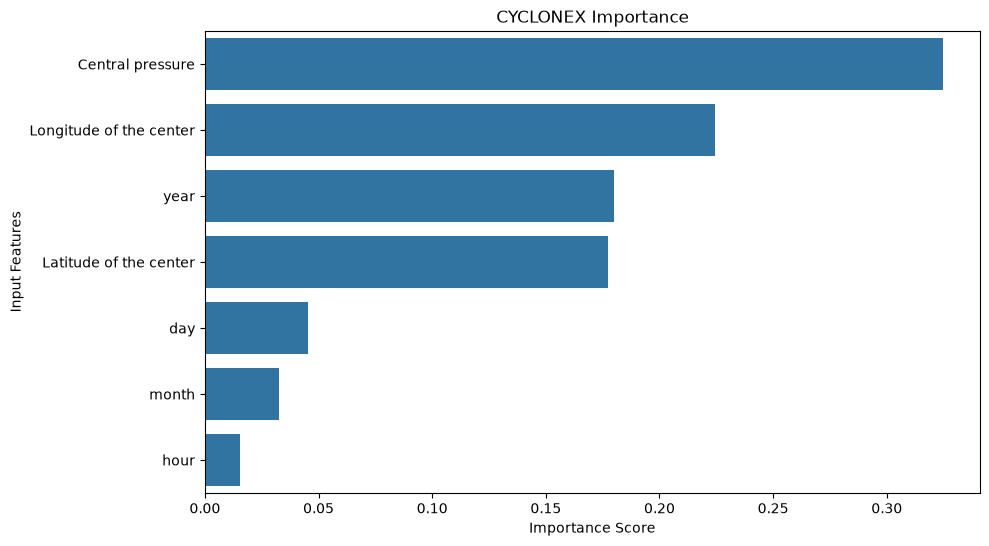

,Feature,Importance
6,Central pressure,0.324736
5,Longitude of the center,0.224434
0,year,0.179963
4,Latitude of the center,0.177243
2,day,0.045170
1,month,0.032803
3,hour,0.015652


In [13]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("CYCLONEX Importance")
plt.xlabel("Importance Score")
plt.ylabel("Input Features")

plt.savefig("cyclonex_figures/feature_importance.png", dpi=300)
plt.show()

display(importance)

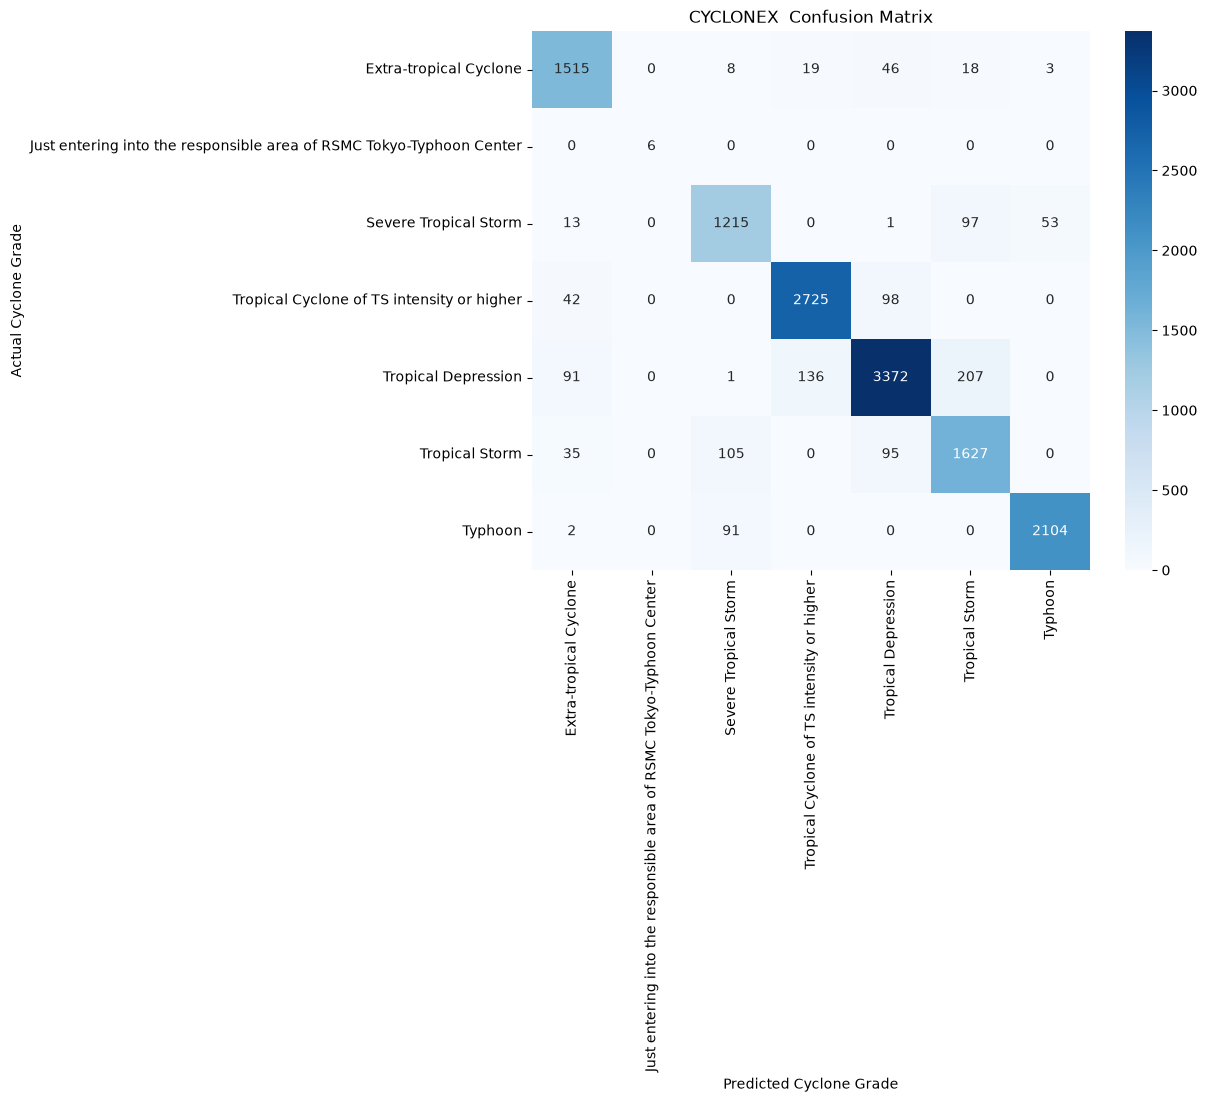

In [14]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Cyclone Grade")
plt.ylabel("Actual Cyclone Grade")

plt.title("CYCLONEX  Confusion Matrix")

plt.savefig("cyclonex_figures/confusion_matrix.png", dpi=300)
plt.show()

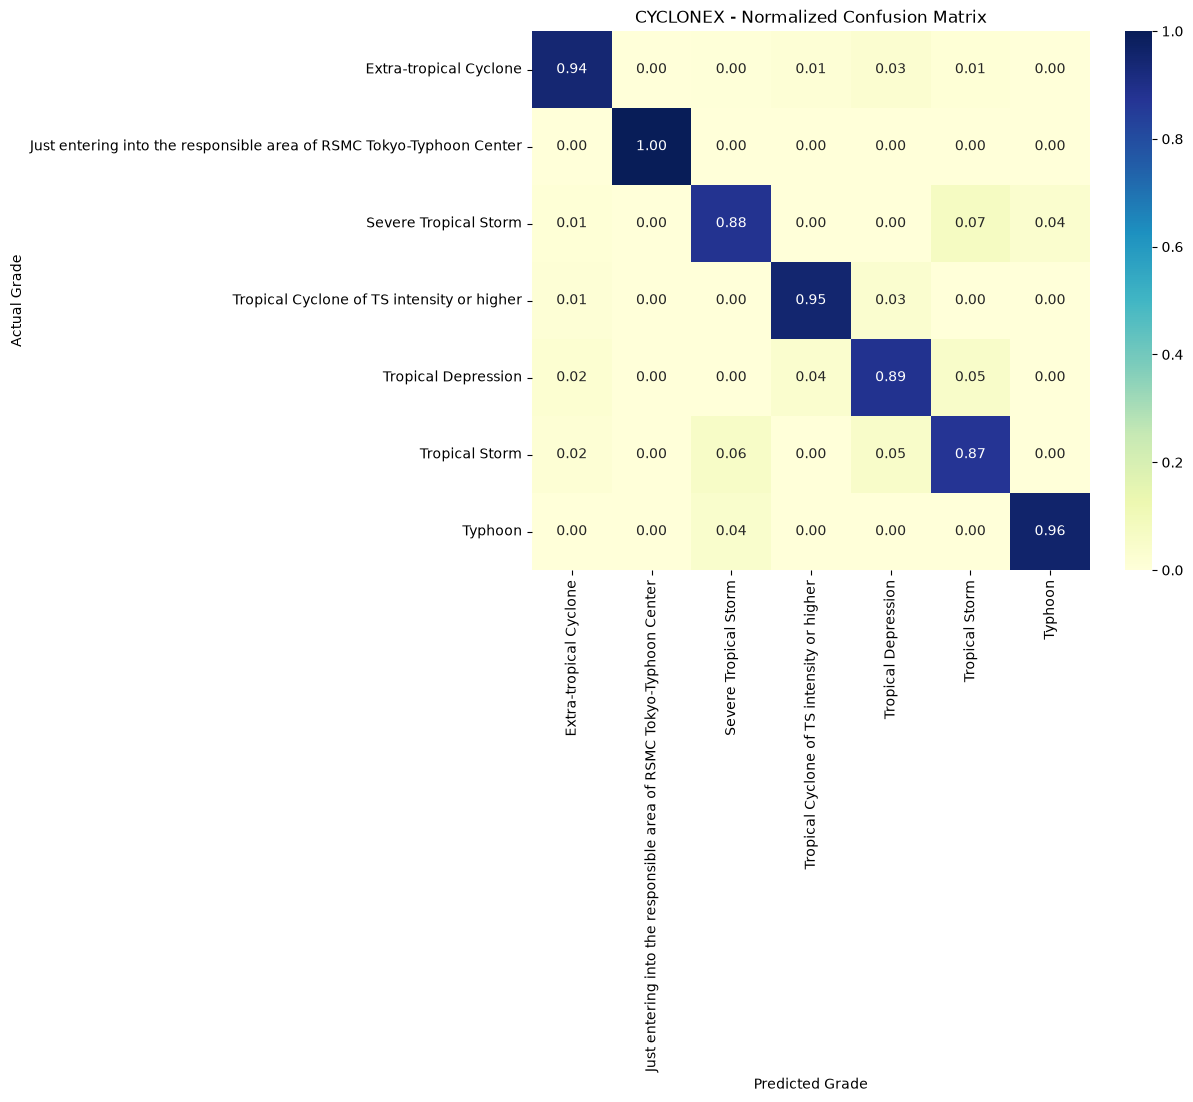

In [15]:
cm_normalized = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    normalize="true"
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Grade")
plt.ylabel("Actual Grade")

plt.title("CYCLONEX - Normalized Confusion Matrix")

plt.savefig("cyclonex_figures/normalized_confusion_matrix.png", dpi=300)
plt.show()

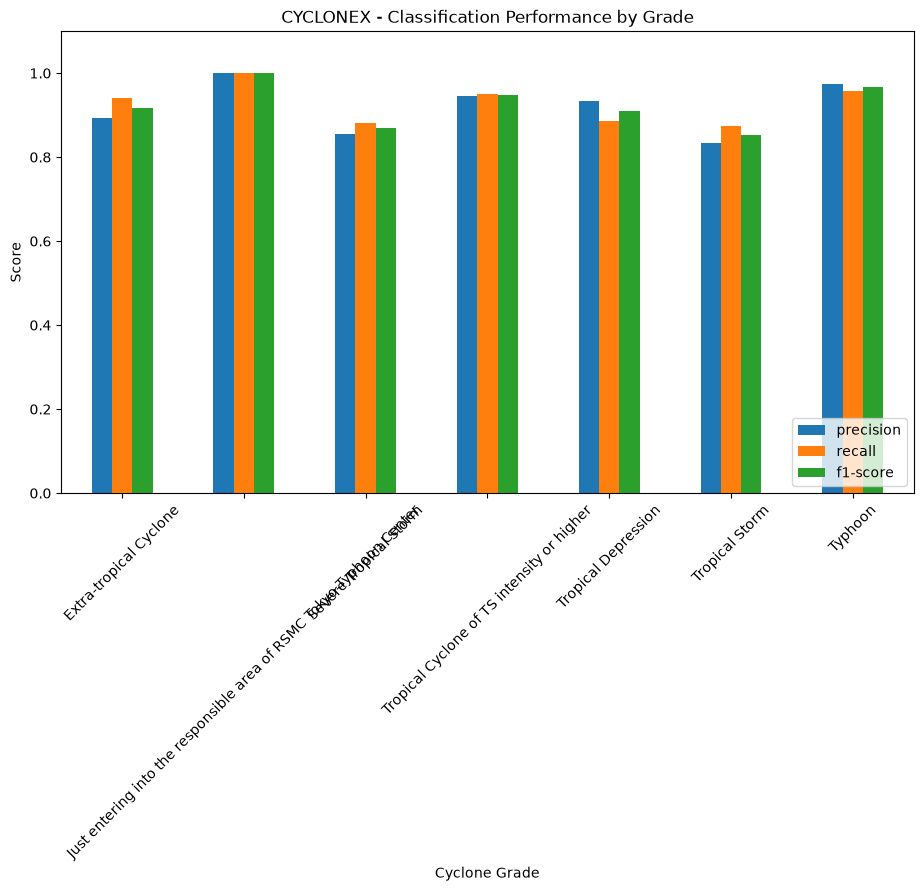

In [16]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

metrics_df = pd.DataFrame(report).T

class_metrics = metrics_df.loc[
    list(label_encoder.classes_),
    ["precision", "recall", "f1-score"]
]

class_metrics.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("CYCLONEX - Classification Performance by Grade")
plt.xlabel("Cyclone Grade")
plt.ylabel("Score")
plt.ylim(0, 1.1)

plt.xticks(rotation=45)
plt.legend(loc="lower right")

plt.savefig("cyclonex_figures/classification_metrics.png", dpi=300)
plt.show()

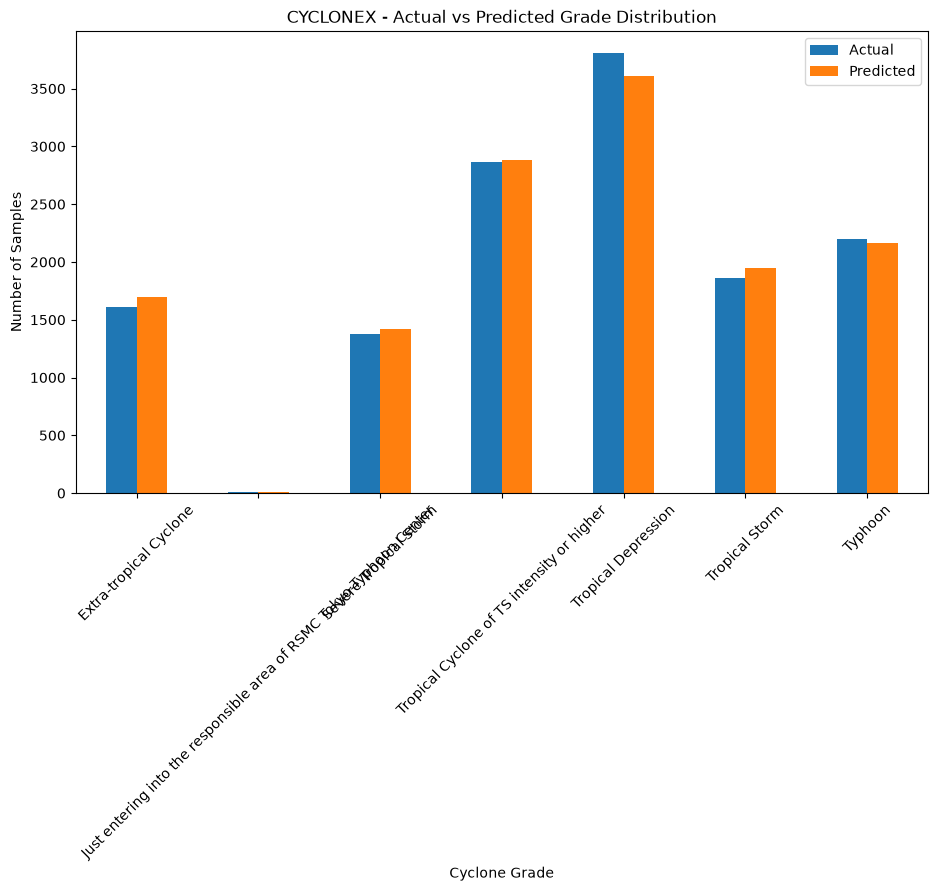

In [17]:
comparison = pd.DataFrame({
    "Actual": label_encoder.inverse_transform(y_test),
    "Predicted": label_encoder.inverse_transform(y_pred)
})

actual_counts = comparison["Actual"].value_counts()
predicted_counts = comparison["Predicted"].value_counts()

grade_comparison = pd.DataFrame({
    "Actual": actual_counts,
    "Predicted": predicted_counts
}).fillna(0)

grade_comparison = grade_comparison.reindex(
    label_encoder.classes_,
    fill_value=0
)

grade_comparison.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("CYCLONEX - Actual vs Predicted Grade Distribution")
plt.xlabel("Cyclone Grade")
plt.ylabel("Number of Samples")

plt.xticks(rotation=45)
plt.legend()

plt.savefig("cyclonex_figures/grade_comparison.png", dpi=300)
plt.show()